# Baseline Model: Logistic Regression

In this notebook, we establish our baseline model. We will use a standard `LogisticRegression` algorithm. 
Because our data is heavily imbalanced (0.13% fraud), we will use `class_weight='balanced'` to penalize the model more for missing fraudulent transactions.

In [1]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
import sys
sys.path.append('..')

from src.preprocessing import load_and_clean_data, preprocess_and_split
from src.feature_engineering import engineer_features
from src.evaluate import evaluate_model

### 1. Load, Engineer Features, and Preprocess
This may take a minute or two because of the large dataset size (6.3M rows).

In [2]:
data_path = '../data/raw/PS_20174392719_1491204439457_log.csv'
print("Loading Data...")
df = load_and_clean_data(data_path)

print("Preprocessing and Splitting (Train/Val/Test)...")
X_train, X_val, X_test, y_train, y_val, y_test, preprocessor = preprocess_and_split(df, val_size=0.15, test_size=0.15, random_state=42)
print("Data ready!")

Loading Data...


Preprocessing and Splitting (Train/Val/Test)...


Data ready!


### 2. Train Logistic Regression
We use `class_weight='balanced'` to tell the model to pay more attention to the minority class (Fraud).

In [3]:
lr = LogisticRegression(class_weight='balanced', max_iter=500, random_state=42)
print("Training model... (this may take a few minutes for 6M rows)")
lr.fit(X_train, y_train)
print("Training complete.")

Training model... (this may take a few minutes for 6M rows)


Training complete.


### 3. Evaluate the Baseline
For fraud detection, our primary metrics are **Recall** (catching fraud) and **PR-AUC** (tradeoff between precision and recall on highly imbalanced data).

Predicting on validation set...
--- Evaluation for Logistic Regression Baseline ---
              precision    recall  f1-score   support

           0       1.00      0.95      0.97    414330
           1       0.05      0.91      0.09      1232

    accuracy                           0.95    415562
   macro avg       0.52      0.93      0.53    415562
weighted avg       1.00      0.95      0.97    415562



ROC-AUC: 0.9779
PR-AUC:  0.5935


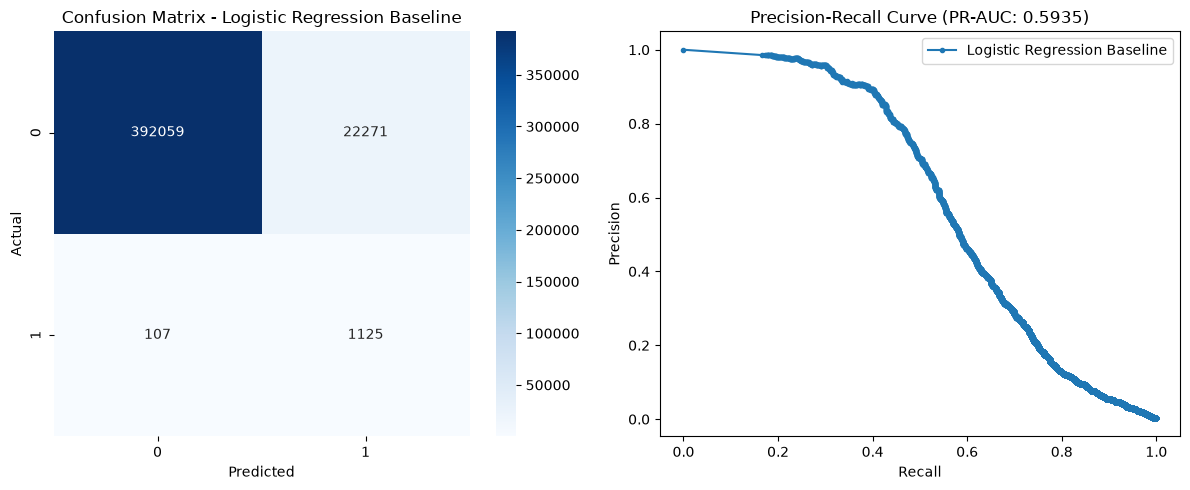

Saved metrics to reports/baseline_metrics.json


In [4]:
import json
print("Predicting on validation set...")
y_pred = lr.predict(X_val)
y_prob = lr.predict_proba(X_val)[:, 1]

metrics = evaluate_model(y_val, y_pred, y_prob, model_name="Logistic Regression Baseline")

with open('../reports/baseline_metrics.json', 'w') as f:
    json.dump(metrics, f, indent=4)
print("Saved metrics to reports/baseline_metrics.json")